<a href="https://colab.research.google.com/github/KaterinaPenaloza/Analisis-de-redes/blob/main/ProyectoRedes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Redes


# Presentación dataset

Para el proyecto de análisis de redes, elegimos el dataset llamado **"moreno_zebra network"**, el cual consiste en una red no dirigida que representa la interacción entre 27 cebras de Grévy en Kenya. Cada nodo representa una cebra y una arista representa que hubo interacción entre dos cebras durante el estudio.

Las columnas del dataset son:
* 1°: ID Nodo origen
* 2°: ID Nodo objetivo

Nosotros renombraremos estas columnas como "Source Zebra" y "Target Zebra" para mayor entendimiento.


# Librerías

In [ ]:
!pip install networkx
!pip install scipy matplotlib

In [39]:
# Análisis de los datos
import pandas as pandas
import numpy as numpy
from scipy.stats import spearmanr   #Calcular coeficiente de Spearman

# Manipulación de grafos
import networkx as nx

# Otros
import random

# Utilizado para las gráficas
import seaborn as sns

# Mostrar gráficas del análisis de datos
import matplotlib.pyplot as plt
from matplotlib import style

# Configuración matplotlib
plt.rcParams['image.cmap'] = "bwr"
plt.rcParams['figure.dpi'] = "64"
plt.rcParams['savefig.bbox'] = "tight"
plt.rcParams['figure.figsize'] = 10, 6.25
plt.style.use('ggplot')

# Configuración warnings
import warnings
warnings.filterwarnings('ignore')

# Pre-procesamiento

In [13]:
# Subir archivo
from google.colab import files
uploaded = files.upload()

# Leer el archivo, usando como delimitación los espacios " "
# Las primeras dos filas son comentarios de encabezado del formato KONECT, por eso se omiten (skiprows=2).
# Definimos los nombres de las columnas por Source Zebra y Target Zebra respectivamente.
df = pandas.read_csv('/content/zebra.txt', delimiter=' ',  skiprows=2,  header=None, names=['Source Zebra', 'Target Zebra'])
df

Saving zebra.txt to zebra.txt


,Source Zebra,Target Zebra
0,1,2
1,1,3
2,1,4
3,1,5
4,1,6
...,...,...
106,24,26
107,24,27
108,25,26
109,25,27


## Limpieza de dataset

Este paso es para asegurarnos de que los datos estén óptimos para su procesamiento más adelante. En primer lugar eliminamos los datos con valores nulos o NaN, luego nos aseguramos de que el tipo de dato sea el correcto (int) y finalmente eliminamos las aristas duplicadas, ordenando cada par de cebras para que la interacción (A, B) y la (B, A) cuenten como una sola.

In [15]:
# Eliminar filas con valores nulos
df.dropna(inplace=True)

# Transformar columnas a int
df = df.astype(int)

# Ordenar cada par (menor, mayor) para que (A,B) y (B,A) cuenten como la misma arista
df[['Source Zebra', 'Target Zebra']] = numpy.sort(df[['Source Zebra', 'Target Zebra']].values, axis=1)

# Eliminar aristas duplicadas
df = df.drop_duplicates().reset_index(drop=True)

df

,Source Zebra,Target Zebra
0,1,2
1,1,3
2,1,4
3,1,5
4,1,6
...,...,...
106,24,26
107,24,27
108,25,26
109,25,27


# Análisis descriptivo de la red


## Medidas de centralidad



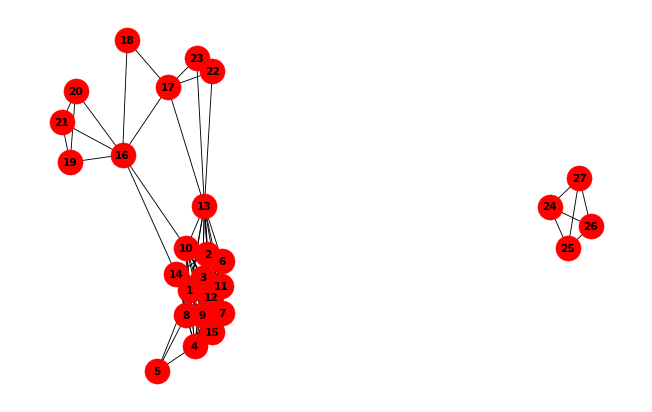

In [33]:
# Crear un grafo desde el DataFrame
G = nx.from_pandas_edgelist(df, 'Source Zebra', 'Target Zebra')

# Posición de los nodos
pos = nx.spring_layout(G, seed=42)

# Visualización del grafo normal
nx.draw(G, pos, node_color='red', node_size=800, with_labels=True, font_weight='bold')
plt.show()


## Grado

La centralidad de grado («degree centrality») es la primera y más simple de las medidas de centralidad. Indica el número de enlaces que posee un nodo con los demás.

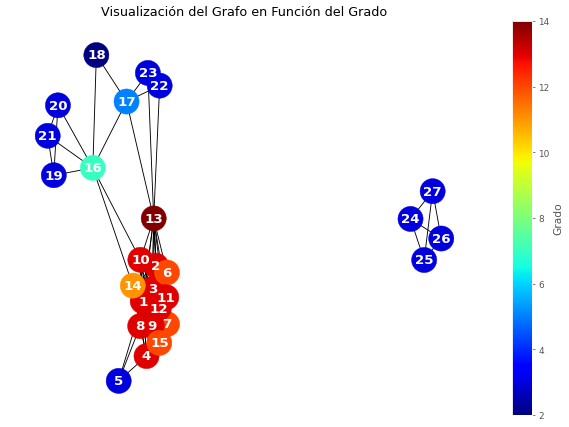

In [34]:
# Calcular medidas de grado
degree = dict(G.degree())

# Obtener colores según el grado de cada nodo
colores = [degree[nodo] for nodo in G.nodes]

# Dibujar el grafo
fig, ax = plt.subplots(figsize=(12, 8))
nx.draw(G, pos, ax=ax, node_color=colores, cmap=plt.cm.jet, node_size=800, with_labels=True, font_size=15, font_color='white', font_weight='bold')

# Añadir barra de colores
sm = plt.cm.ScalarMappable(cmap=plt.cm.jet, norm=plt.Normalize(vmin=min(degree.values()), vmax=max(degree.values())))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('Grado')
ax.set_title('Visualización del Grafo en Función del Grado')

plt.show()

## Closeness

La medida de cercanía, se basa en calcular la suma o bien el promedio de las distancias más cortas desde un nodo hacia todos los demás. La cercanía mide de alguna forma la accesibilidad de un nodo en la red, cuando mas cercano es el acceso a los demas nodos, mas alta su valoración

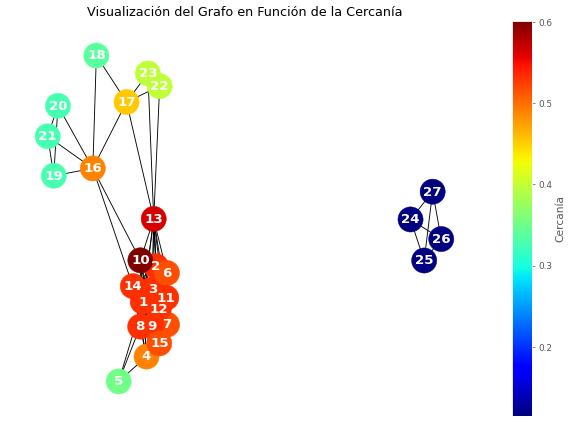

In [35]:
# Calcular medida de cercanía (closeness)
closeness = nx.closeness_centrality(G)

# Obtener colores según la cercanía de cada nodo
colores = [closeness[nodo] for nodo in G.nodes]

# Dibujar el grafo
fig, ax = plt.subplots(figsize=(12, 8))
nx.draw(G, pos, ax=ax, node_color=colores, cmap=plt.cm.jet, node_size=800, with_labels=True, font_size=15, font_color='white', font_weight='bold')

# Añadir barra de colores
sm = plt.cm.ScalarMappable(cmap=plt.cm.jet, norm=plt.Normalize(vmin=min(closeness.values()), vmax=max(closeness.values())))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('Cercanía')
ax.set_title('Visualización del Grafo en Función de la Cercanía')

plt.show()

## Betweenness
La intermediación («betweenness centrality») es una medida que cuantifica la frecuencia o el número de veces que un nodo actúa como un puente a lo largo del camino más corto entre otros dos nodos.
En otras palabras, cuantos mas nodos que necesiten pasar por mi para hacer sus conexiones indirectas por los caminos más cortos, más central seré yo.

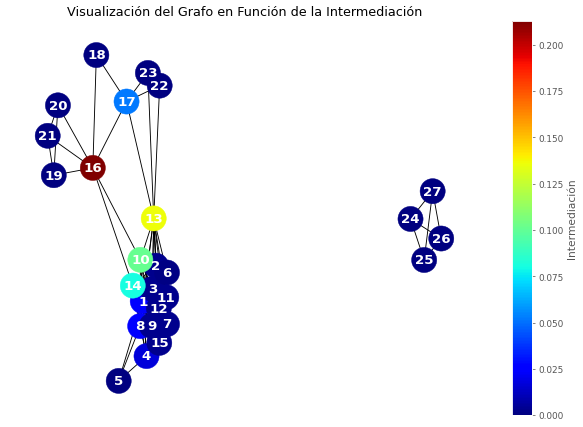

In [36]:
# Calcular medida de intermediación (betweenness)
betweenness = nx.betweenness_centrality(G)

# Obtener colores según la intermediación de cada nodo
colores = [betweenness[nodo] for nodo in G.nodes]

# Dibujar el grafo
fig, ax = plt.subplots(figsize=(12, 8))
nx.draw(G, pos, ax=ax, node_color=colores, cmap=plt.cm.jet, node_size=800, with_labels=True, font_size=15, font_color='white', font_weight='bold')

# Añadir barra de colores
sm = plt.cm.ScalarMappable(cmap=plt.cm.jet, norm=plt.Normalize(vmin=min(betweenness.values()), vmax=max(betweenness.values())))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('Intermediación')
ax.set_title('Visualización del Grafo en Función de la Intermediación')

plt.show()

## PageRank

El PageRank es un algoritmo desarrollado por Larry Page y Sergey Brin, fundadores de Google, para medir la importancia relativa de los nodos de una red. Su idea central es que un nodo es importante si está conectado a otros nodos importantes: no solo cuenta cuántas conexiones tiene, sino también la importancia de quienes se conectan con él. Cada nodo recibe un valor entre 0 y 1 (la suma de todos los valores es 1), que se puede interpretar como la probabilidad de encontrarse en ese nodo después de recorrer la red al azar durante mucho tiempo. En esta red, un PageRank alto indica que la cebra participa en interacciones con otras cebras bien conectadas.

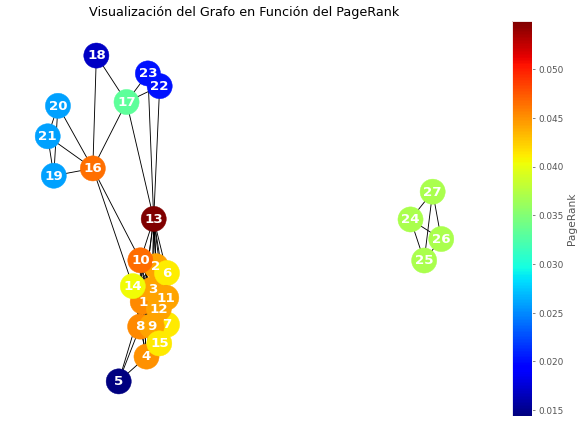

In [37]:
# Calcular PageRank
pagerank = nx.pagerank(G)

# Obtener colores según el PageRank de cada nodo
colores = [pagerank[nodo] for nodo in G.nodes]

# Dibujar el grafo
fig, ax = plt.subplots(figsize=(12, 8))
nx.draw(G, pos, ax=ax, node_color=colores, cmap=plt.cm.jet, node_size=800, with_labels=True, font_size=15, font_color='white', font_weight='bold')

# Añadir barra de colores
sm = plt.cm.ScalarMappable(cmap=plt.cm.jet, norm=plt.Normalize(vmin=min(pagerank.values()), vmax=max(pagerank.values())))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('PageRank')
ax.set_title('Visualización del Grafo en Función del PageRank')

plt.show()

In [38]:
# Crear un DataFrame para almacenar las medidas
medidas_df = pandas.DataFrame({
    'Nodo': list(degree.keys()),
    'Grado': list(degree.values()),
    'Cercanía': list(closeness.values()),
    'Intermediación': list(betweenness.values()),
    'PageRank': list(pagerank.values())
})
medidas_df

,Nodo,Grado,Cercanía,Intermediación,PageRank
0,1,13,0.531868,0.024031,0.045369
1,2,13,0.531868,0.003133,0.044276
2,3,13,0.531868,0.003133,0.044276
3,4,13,0.489879,0.017254,0.044985
4,5,3,0.351234,0.000000,0.014430
5,6,12,0.517094,0.001589,0.041136
6,7,12,0.517094,0.002877,0.041281
7,8,13,0.531868,0.024031,0.045369
8,9,13,0.531868,0.003133,0.044276
9,10,13,0.600496,0.101441,0.046647


Interpretaciones generales:

1. **Grado:**
   - Los nodos (cebras) 1, 2, 3, 4, 8, 9, 10, 11, 12 y 13 tienen un grado alto, lo que indica que están conectados con muchos otros nodos (cebras). La cebra 13 tiene el grado más alto.
   - Los nodos 5, 18, 19, 20, 21, 22, 23, 24, 25, 26 y 27 tienen un grado mucho menor, lo que indica que están menos conectados en comparación con las otras cebras, incluso se puede apreciar en el grafo que las cebras 24, 25, 26 y 27 están aisladas del resto de cebras.

2. **Cercanía:**
   - Los nodos 10 y 13 tienen una cercanía relativamente alta, lo que sugiere que están cerca de muchos otros nodos en términos de distancia geodésica.
   - Los nodos 24, 25, 26 y 27 tienen una cercanía más baja, indicando que efectivamente como se puede ver en el grafo, están más alejados de los otros nodos en términos de distancia geodésica.

3. **Intermediación:**
   - El nodo 16 y 13 tienen intermediación alta, lo que nos dice que actúa como un puente entre muchos pares de nodos.
   - Los nodos 5, 18, 19, 20, 21, 22, 23, 24, 25, 26 y 27 tienen una intermediación cero, lo que indica que no están en la ruta más corta entre otros nodos.

4. **PageRank:**
   - El nodo 13 tienen el PageRank más alto, sugiriendo que es el más importante según el algoritmo PageRank.
   - El nodo 5 tiene el PageRank más bajo, por lo que sería el nodo menos importante según este algoritmo.
   - Las cebras 24, 25, 26 y 27, aunque están aisladas del resto, tienen un PageRank de 0,037, mayor al de otras cebras con el mismo grado. Esto se debe a que forman un grupo cerrado donde la importancia se reparte solo entre ellas.


# Análisis correlacional de la red

En esta sección analizamos si las medidas de centralidad realmente identifican a las cebras más influyentes, mediante una simulación de propagación de un comportamiento por la red y una correlación de Spearman entre las cuatro medidas.

##Propagación de influencia

###¿Qué medida de centralidad elige mejor a las cebras iniciales?

Para comprobar si las medidas de centralidad sirven en la práctica, simulamos cómo se propaga un comportamiento por la red con el *linear threshold*:

* Cada cebra tiene un umbral aleatorio entre 0 y 1.
* Una cebra adopta el comportamiento cuando la fracción de sus vecinas que ya lo adoptó alcanza su umbral.
* Quien adopta el comportamiento ya no lo abandona.

Elegimos 3 cebras iniciales con cada medida (grado, cercanía, intermediación y PageRank) y también 3 al azar como comparación. Repetimos la simulación 1.000 veces y comparamos cuántas cebras alcanza en promedio cada estrategia.

In [40]:
# Función para calcular la dispersión de influencia
def linear_threshold(grafo, semillas, rng):
    # Umbral aleatorio en (0, 1] para cada cebra
    umbrales = {nodo: 1 - rng.random() for nodo in grafo.nodes()}
    activos = set(semillas)
    cambio = True

    while cambio:
        cambio = False
        for nodo in grafo.nodes():
            if nodo in activos:
                continue
            vecinos = list(grafo.neighbors(nodo))
            if vecinos:
                fraccion_activa = sum(v in activos for v in vecinos) / len(vecinos)
                if fraccion_activa >= umbrales[nodo]:
                    activos.add(nodo)
                    cambio = True
    return activos

def top_nodos(medida, k=3):
    # Devuelve los k nodos con mayor valor (en empates, gana el de menor ID).
    return sorted(medida, key=lambda nodo: (-medida[nodo], nodo))[:k]


Cebras iniciales por estrategia: {'Grado': [13, 1, 2], 'Cercanía': [10, 13, 1], 'Intermediación': [16, 13, 10], 'PageRank': [13, 10, 16]}


,Estrategia,Promedio de cebras alcanzadas,Desviación estándar
3,PageRank,14.279,5.508826
2,Intermediación,14.023,5.624986
1,Cercanía,13.896,5.099136
0,Grado,13.213,5.374908
4,Aleatorio,11.346,6.039063


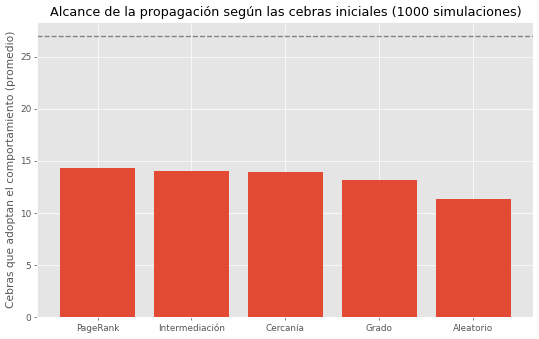

In [42]:
K = 3          # cantidad de cebras iniciales
N_SIM = 1000   # número de simulaciones

estrategias = {
    'Grado': top_nodos(degree, K),
    'Cercanía': top_nodos(closeness, K),
    'Intermediación': top_nodos(betweenness, K),
    'PageRank': top_nodos(pagerank, K),
}
print("Cebras iniciales por estrategia:", estrategias)

rng = random.Random(42)
resultados = {nombre: [] for nombre in list(estrategias) + ['Aleatorio']}

for _ in range(N_SIM):
    for nombre, semillas in estrategias.items():
        resultados[nombre].append(len(linear_threshold(G, semillas, rng)))
    resultados['Aleatorio'].append(
        len(linear_threshold(G, rng.sample(list(G.nodes()), K), rng)))

resumen = pandas.DataFrame({
    'Estrategia': list(resultados.keys()),
    'Promedio de cebras alcanzadas': [numpy.mean(v) for v in resultados.values()],
    'Desviación estándar': [numpy.std(v) for v in resultados.values()],
}).sort_values('Promedio de cebras alcanzadas', ascending=False)

display(resumen)

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(resumen['Estrategia'], resumen['Promedio de cebras alcanzadas'])
ax.axhline(len(G.nodes()), linestyle='--', color='gray')
ax.set_ylabel('Cebras que adoptan el comportamiento (promedio)')
ax.set_title(f'Alcance de la propagación según las cebras iniciales ({N_SIM} simulaciones)')

plt.show()

Elegir las cebras iniciales con cualquier medida de centralidad propaga el comportamiento a más cebras que elegirlas al azar (entre 13 y 14 cebras en promedio, frente a 11).

Entre las medidas, PageRank, intermediación y cercanía obtienen resultados muy parecidos, mientras que el grado, que solo cuenta conexiones, queda algo por debajo. Esto sugiere que importa más dónde está conectada una cebra que cuántas conexiones tiene.

Las diferencias entre las tres mejores son pequeñas comparadas con la variabilidad de las simulaciones (desviación de unas 5 cebras), así que no se puede afirmar que una sea claramente mejor que otra. Además, ninguna estrategia llega a las 27 cebras: el grupo formado por las cebras 24, 25, 26 y 27 está desconectado del resto y solo se activa si alguna de ellas es cebra inicial.

## Coeficiente de correlación de Spearman

La matriz de correlaciones de Spearman muestra la correlación entre cuatro variables: grado, cercanía, intermediación y PageRank. Los valores de la matriz van de -1 a 1, donde 1 indica una correlación perfecta positiva, -1 indica una correlación perfecta negativa y 0 indica que no hay correlación.

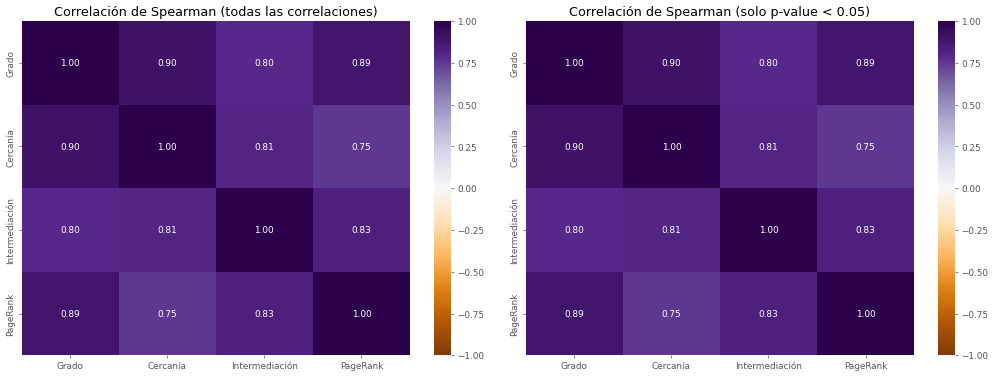

,Grado,Cercanía,Intermediación,PageRank
Grado,0.000000e+00,1.634126e-10,6.721582e-07,5.360931e-10
Cercanía,1.634126e-10,0.000000e+00,2.968332e-07,5.918171e-06
Intermediación,6.721582e-07,2.968332e-07,0.000000e+00,7.999141e-08
PageRank,5.360931e-10,5.918171e-06,7.999141e-08,0.000000e+00


In [43]:
import seaborn as sns
from scipy.stats import spearmanr

# Usamos las medidas calculadas sobre la red de cebras (medidas_df)
variables = ['Grado', 'Cercanía', 'Intermediación', 'PageRank']
datos = medidas_df[variables]

# Coeficiente de Spearman y p-values
rho, pvalues = spearmanr(datos)
rho_df = pandas.DataFrame(rho, index=variables, columns=variables)
p_df = pandas.DataFrame(pvalues, index=variables, columns=variables)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matriz completa
sns.heatmap(rho_df, annot=True, cmap="PuOr", fmt=".2f", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Correlación de Spearman (todas las correlaciones)')

# Solo correlaciones significativas (p < 0.05)
sns.heatmap(rho_df, annot=True, cmap="PuOr", fmt=".2f", vmin=-1, vmax=1,
            mask=(p_df >= 0.05), ax=axes[1])
axes[1].set_title('Correlación de Spearman (solo p-value < 0.05)')

plt.tight_layout()
plt.show()

# Resultado p-values
p_df

En cuanto a la matriz de correlaciones de Spearman, se puede ver que existe una correlación positiva y fuerte entre el grado, la cercanía, la intermediación y el PageRank, con coeficientes que van desde 0,75 hasta 0,90. Esto significa que, en general, las cebras que destacan según una de estas medidas también tienden a destacar según las demás. Además, al filtrar por p-value < 0,05, todas las correlaciones se mantienen (el p-value más alto es de aproximadamente 0,000006), por lo que ninguna se debe al azar y ambas matrices resultan idénticas.

En particular, la correlación entre el grado y la cercanía es de 0,90, la más alta de toda la matriz. Esto significa que las cebras con muchas interacciones tienden a estar a pocos pasos del resto de la red, lo que tiene sentido, ya que mientras más vecinas directas se tienen, más cerca se está de las demás.

La correlación entre el grado y el PageRank es de 0,89, lo que también indica una correlación muy fuerte. Esto significa que las cebras con un grado alto tienden a tener un PageRank alto, porque el PageRank depende en buena medida del número de conexiones que recibe un nodo, aunque también toma en cuenta qué tan importantes son esas conexiones.

La correlación entre la intermediación y el PageRank es de 0,83, y la que hay entre la cercanía y la intermediación es de 0,81. Ambas son fuertes, y significan que las cebras bien conectadas y cercanas al resto también tienden a ser puentes en los caminos más cortos entre otras cebras.

La correlación entre el grado y la intermediación es de 0,80, que sigue siendo fuerte pero es la menor de las relaciones que involucran al grado. Esto se debe a que tener muchas conexiones no garantiza ser un buen intermediario: la cebra 16, por ejemplo, tiene un grado moderado (7) y sin embargo es la de mayor intermediación (0,21), porque conecta a un grupo de cebras que, de otra forma, estarían más alejadas del resto. En cambio, varias cebras con grado 13 tienen una intermediación muy baja, ya que sus vecinas también están conectadas entre sí.

Finalmente, la correlación entre la cercanía y el PageRank es de 0,75, la más débil de la matriz, aunque sigue siendo fuerte. Esto se explica en parte por las cebras 24, 25, 26 y 27, que forman un grupo separado del resto de la red: tienen un grado de 3, igual que otras cebras, y un PageRank (0,037) relativamente alto para ese grado, porque la importancia queda repartida solo entre ellas, pero su cercanía es muy baja (0,115) por estar desconectadas de las demás. Al ser cebras con un PageRank relativamente alto y una cercanía muy baja, debilitan la relación entre ambas medidas.

En conclusión, las cuatro medidas de centralidad están fuertemente relacionadas, por lo que las cebras más centrales de la red lo son según varios criterios a la vez. Sin embargo, no miden exactamente lo mismo, y las diferencias más claras aparecen cuando una cebra es un puente entre grupos (alta intermediación con grado moderado) o cuando pertenece a un grupo aislado (como las cebras 24 a 27).

# Interpretación de resultados

En este proyecto analizamos la red de interacciones entre 27 cebras de Grévy en Kenia, compuesta por 111 interacciones, usando medidas de centralidad, una simulación de propagación y la correlación de Spearman.

Las medidas de centralidad muestran que la red tiene un núcleo de cebras muy conectadas (la mayoría con 13 o 14 interacciones) y un grupo de cebras con pocas conexiones. Además, las cebras 24, 25, 26 y 27 forman un grupo completamente separado del resto de la red, por lo que no interactúan con ninguna de las otras cebras del estudio. También se destacan la cebra 13, con el mayor grado, y la cebra 16, que tiene un grado moderado (7) pero la mayor intermediación (0,21), ya que actúa como puente entre un grupo de cebras y el resto de la red.

Para ver si estas medidas sirven en la práctica, simulamos la propagación de un comportamiento con el modelo de umbral lineal, eligiendo 3 cebras iniciales con cada medida y repitiendo la simulación 1.000 veces. Elegir las cebras iniciales con cualquier medida de centralidad alcanza en promedio entre 13 y 14 cebras, frente a unas 11 cuando se eligen al azar. PageRank, intermediación y cercanía obtienen resultados muy parecidos entre sí, y el grado queda algo por debajo, lo que sugiere que importa más la posición de una cebra en la red que su cantidad de conexiones. Sin embargo, las diferencias entre las mejores estrategias son pequeñas en comparación con la variabilidad de las simulaciones, por lo que no se puede afirmar que una sea claramente superior. Por otro lado, ninguna estrategia llega a las 27 cebras, porque el grupo formado por las cebras 24 a 27 queda desconectado del resto.

La correlación de Spearman entre las cuatro medidas es positiva, fuerte y significativa (entre 0,75 y 0,90), lo que indica que las cebras que son centrales según una medida suelen serlo también según las demás. Las diferencias aparecen en casos particulares, como la cebra 16 (alta intermediación con grado moderado) o el grupo aislado de las cebras 24 a 27, y muestran que cada medida describe un aspecto distinto de la posición de una cebra en la red.

Como limitaciones, la red es pequeña (27 nodos), tiene muchos valores repetidos y no incluye información sobre el contexto de las interacciones, y la propagación se simuló con un modelo teórico y no con datos reales de contagio. Aun así, el análisis permite identificar qué cebras ocupan posiciones clave en la estructura social de la población, lo que podría ser un punto de partida para estudiar cómo se transmite información o comportamientos entre ellas.

# Bibliografía

1. Siva R Sundaresan, Ilya R Fischhoff, Jonathan Dushoff, and Daniel I Rubenstein. Network metrics reveal differences in social organization between two fission–fusion species, Grevy's zebra and onager. Oecologia, 151(1):140–149, 2007.
2. http://konect.cc/networks/moreno_zebra/
3. Jérôme Kunegis. KONECT – The Koblenz Network Collection. In Proc. Int. Conf. on World Wide Web Companion, pages 1343–1350, 2013.
4. Diapositivas del aula virtual